# Notebook 2 — Active Learning on Edibility Buckets

Compare active-learning query strategies on **4-class edibility classification** (SAFE / COOK_FIRST / AVOID / UNCERTAIN) using frozen CLIP ViT-B/32 embeddings.

## Why 4 classes (not 179 species)

The original 179-way species classification proved too challenging with this label budget: even at 3000 labeled samples, accuracy topped out at 14-19% (random baseline = 0.56%). While AL strategies showed some differentiation there (margin beat random by ~5 points), **drawing conclusions from such a weak base task is unreliable** — the differences could be noise within a failure mode.

We switch to the downstream task that users actually care about: **edibility category**. This task:
- Has a reasonable ceiling (linear probe on frozen CLIP typically reaches 70-85% on coarse categories)
- Preserves meaningful long-tail structure (AVOID 57%, COOK_FIRST 21%, SAFE 15%, UNCERTAIN 7%)
- Directly maps to real-world user interaction

## What we measure

For each (strategy × seed):

- **Top-1 accuracy** on the held-out test set
- **Macro F1** — rewards strategies that learn minority classes (especially UNCERTAIN at 7%)
- **Per-bucket recall** — AVOID recall is safety-critical; UNCERTAIN recall tests epistemic behavior
- **Per-genus accuracy** — does the classifier perform uniformly across genera?

## Loads

Outputs from Notebook 1 (`artifacts/df20m_embeddings.npy`, `df20m_metadata.csv`) and Notebook 00 (`species_edibility_with_buckets.csv`).


In [18]:
# ==================== IMPORTS ====================
import json
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, recall_score, classification_report
from sklearn.exceptions import ConvergenceWarning

warnings.filterwarnings('ignore', category=ConvergenceWarning)
warnings.filterwarnings('ignore', category=UserWarning, module='sklearn')
warnings.filterwarnings('ignore', category=FutureWarning)

In [19]:
# ==================== CONFIG ====================
ARTIFACTS_DIR = Path('artifacts')
RESULTS_DIR   = Path('results')
RESULTS_DIR.mkdir(exist_ok=True, parents=True)

# Bucket task config
BUCKET_ORDER  = ['SAFE', 'COOK_FIRST', 'AVOID', 'UNCERTAIN']
N_CLASSES     = len(BUCKET_ORDER)

# AL loop config — scaled for a 4-class task
N_INIT            = 400          # ~100 per class average at 4 classes
BATCH_SIZE        = 100          # labels per round
MAX_LABELS        = 3000         # total budget cap
N_SEEDS           = 5            # for error bars
TARGET_ACC        = 0.75         # 'labels-to-target' threshold (refine after first run)
TARGET_MACRO_F1   = 0.60

# Base classifier
def make_classifier():
    return LogisticRegression(
        max_iter=1000,
        n_jobs=-1,
        solver='lbfgs',
        C=1.0,                    # default; strong regularization fine for 4-class
    )

## Step 1 — Load Embeddings, Metadata, and Bucket Labels

Build a clean dataset where every image has a 4-class bucket label.

In [20]:
embeddings   = np.load(ARTIFACTS_DIR / 'df20m_embeddings.npy')
metadata     = pd.read_csv(ARTIFACTS_DIR / 'df20m_metadata.csv')
buckets_df   = pd.read_csv(ARTIFACTS_DIR / 'species_edibility_with_buckets.csv')

metadata['species_id']    = metadata['species_id'].astype(int)
metadata['embedding_idx'] = metadata['embedding_idx'].astype(int)

# Map species name → bucket index
bucket_to_idx = {b: i for i, b in enumerate(BUCKET_ORDER)}
species_name_to_bucket_idx = {
    row['species']: bucket_to_idx[row['bucket']]
    for _, row in buckets_df.iterrows()
}

# Attach bucket_id to each image via its species name
metadata['bucket_id'] = metadata['species'].map(species_name_to_bucket_idx)

# Any images whose species is missing from the bucket map?
missing = metadata['bucket_id'].isna().sum()
if missing > 0:
    print(f"WARNING: {missing} images have species not in bucket map — treating as UNCERTAIN")
    metadata['bucket_id'] = metadata['bucket_id'].fillna(bucket_to_idx['UNCERTAIN'])
metadata['bucket_id'] = metadata['bucket_id'].astype(int)

# Pool / test split
train_mask = metadata['split'].values == 'train'
test_mask  = metadata['split'].values == 'test'

X_pool = embeddings[train_mask]
y_pool = metadata.loc[train_mask, 'bucket_id'].to_numpy()   # 4-class labels
X_test = embeddings[test_mask]
y_test = metadata.loc[test_mask, 'bucket_id'].to_numpy()

# Genus info (for per-genus reporting; NOT used as training label)
test_genus_arr = metadata.loc[test_mask, 'genus'].to_numpy()

print(f"Pool:  {X_pool.shape[0]:,} samples, {X_pool.shape[1]} dims")
print(f"Test:  {X_test.shape[0]:,} samples")
print(f"Classes: {N_CLASSES}  ({BUCKET_ORDER})")
print(f"\nTrain bucket distribution:")
for i, b in enumerate(BUCKET_ORDER):
    n = (y_pool == i).sum()
    print(f"  {b:12s} {n:6,d} ({100*n/len(y_pool):5.1f}%)")
print(f"\nTest bucket distribution:")
for i, b in enumerate(BUCKET_ORDER):
    n = (y_test == i).sum()
    print(f"  {b:12s} {n:6,d} ({100*n/len(y_test):5.1f}%)")

Pool:  32,724 samples, 512 dims
Test:  3,637 samples
Classes: 4  (['SAFE', 'COOK_FIRST', 'AVOID', 'UNCERTAIN'])

Train bucket distribution:
  SAFE          4,898 ( 15.0%)
  COOK_FIRST    6,875 ( 21.0%)
  AVOID        18,652 ( 57.0%)
  UNCERTAIN     2,299 (  7.0%)

Test bucket distribution:
  SAFE            546 ( 15.0%)
  COOK_FIRST      764 ( 21.0%)
  AVOID         2,073 ( 57.0%)
  UNCERTAIN       254 (  7.0%)


## Step 1.5 — Upper-Bound Sanity Baseline

Fit LR on the **full training pool** — this tells us the ceiling the AL experiments are approaching. If this is already close to 1.0 the task is too easy. If it's near random (25%), something is wrong with embeddings or labels.

In [21]:
# Full-supervision ceiling
full_model = make_classifier()
full_model.fit(X_pool, y_pool)
y_pred_full = full_model.predict(X_test)

full_acc = accuracy_score(y_test, y_pred_full)
full_f1  = f1_score(y_test, y_pred_full, average='macro', zero_division=0)
print(f"Full-supervision ({len(X_pool):,} labels):")
print(f"  Accuracy:    {full_acc:.3f}")
print(f"  Macro F1:    {full_f1:.3f}")

# Per-bucket recall on full supervision
per_bucket_recall_full = recall_score(
    y_test, y_pred_full, average=None, zero_division=0,
    labels=list(range(N_CLASSES)),
)
print(f"\n  Per-bucket recall (full supervision):")
for i, b in enumerate(BUCKET_ORDER):
    print(f"    {b:12s} {per_bucket_recall_full[i]:.3f}")

# Random-guess baseline: always predict majority class (AVOID)
majority_class = int(np.argmax(np.bincount(y_pool)))
majority_acc = (y_test == majority_class).mean()
print(f"\nMajority-class baseline (always predict '{BUCKET_ORDER[majority_class]}'):")
print(f"  Accuracy: {majority_acc:.3f}   (this is what any AL strategy must beat)")

Full-supervision (32,724 labels):
  Accuracy:    0.660
  Macro F1:    0.460

  Per-bucket recall (full supervision):
    SAFE         0.478
    COOK_FIRST   0.385
    AVOID        0.884
    UNCERTAIN    0.051

Majority-class baseline (always predict 'AVOID'):
  Accuracy: 0.570   (this is what any AL strategy must beat)


## Step 2 — Evaluation Function

In [22]:
def evaluate(model, X_test, y_test, test_genus_arr, classes_seen):
    """Evaluate on the fixed held-out test set (4-class)."""
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    f1  = f1_score(y_test, y_pred, average='macro', zero_division=0)

    # Per-bucket recall
    per_bucket_recall = recall_score(
        y_test, y_pred, average=None, zero_division=0,
        labels=list(range(N_CLASSES)),
    )
    bucket_metrics = {
        f'recall_{BUCKET_ORDER[i]}': per_bucket_recall[i]
        for i in range(N_CLASSES)
    }

    # Per-genus accuracy (diagnostic only — genus not used in training)
    per_genus = {}
    for g in np.unique(test_genus_arr):
        m = test_genus_arr == g
        per_genus[f'acc_{g}'] = accuracy_score(y_test[m], y_pred[m])

    return {
        'accuracy':       acc,
        'macro_f1':       f1,
        'n_classes_seen': len(classes_seen),
        **bucket_metrics,
        **per_genus,
    }

## Step 3 — Query Strategies

Five strategies:

- **random** — uniform baseline
- **entropy** — highest predictive entropy (traditional uncertainty sampling)
- **margin** — smallest gap between top-1 and top-2 class probabilities (often stronger than entropy in multi-class)
- **coreset** — k-center greedy in embedding space; coverage-based
- **cb_entropy** — entropy reweighted by inverse-sqrt class frequency; designed to surface minority classes (UNCERTAIN in particular)

In [23]:
def query_random(X_labeled, y_labeled, X_unlabeled, model, batch_size, rng):
    return rng.choice(len(X_unlabeled), size=batch_size, replace=False)


def query_entropy(X_labeled, y_labeled, X_unlabeled, model, batch_size, rng):
    p = model.predict_proba(X_unlabeled)
    entropy = -np.sum(p * np.log(p + 1e-12), axis=1)
    return np.argsort(entropy)[-batch_size:]


def query_margin(X_labeled, y_labeled, X_unlabeled, model, batch_size, rng):
    p = model.predict_proba(X_unlabeled)
    p_sorted = np.sort(p, axis=1)
    margin = p_sorted[:, -1] - p_sorted[:, -2]
    return np.argsort(margin)[:batch_size]


def query_coreset(X_labeled, y_labeled, X_unlabeled, model, batch_size, rng):
    """K-center greedy; cosine distance on L2-normalized CLIP features."""
    sim_to_labeled = X_unlabeled @ X_labeled.T
    min_dist = 1.0 - sim_to_labeled.max(axis=1)
    picked = []
    for _ in range(batch_size):
        idx = int(np.argmax(min_dist))
        picked.append(idx)
        new_sim = X_unlabeled @ X_unlabeled[idx]
        min_dist = np.minimum(min_dist, 1.0 - new_sim)
        min_dist[idx] = -np.inf
    return np.array(picked)


def make_class_balanced_entropy(train_class_freq):
    weights = 1.0 / np.sqrt(train_class_freq + 1)
    weights = weights / weights.sum()
    def _strategy(X_labeled, y_labeled, X_unlabeled, model, batch_size, rng):
        p = model.predict_proba(X_unlabeled)
        entropy = -np.sum(p * np.log(p + 1e-12), axis=1)
        pred_class = p.argmax(axis=1)
        pred_global = model.classes_[pred_class]
        tail_weight = weights[pred_global]
        score = entropy * tail_weight
        return np.argsort(score)[-batch_size:]
    return _strategy

## Step 4 — Stratified Init

For 4 classes, we can afford ~100 samples per class from the start, giving every class solid initial coverage. Using `max_per_class` caps head classes so AVOID doesn't dominate.

In [24]:
def stratified_init(X_pool, y_pool, n_init, n_classes, rng, max_per_class=None):
    target_per_class = n_init // n_classes
    if max_per_class is not None:
        target_per_class = min(target_per_class, max_per_class)
    target_per_class = max(target_per_class, 1)

    picked = []
    for c in range(n_classes):
        class_idx = np.where(y_pool == c)[0]
        if len(class_idx) == 0:
            continue
        take = min(target_per_class, len(class_idx))
        picked.extend(rng.choice(class_idx, size=take, replace=False).tolist())

    picked = np.array(picked)

    if len(picked) < n_init:
        remaining = np.setdiff1d(np.arange(len(X_pool)), picked)
        extra_n = min(n_init - len(picked), len(remaining))
        extra = rng.choice(remaining, size=extra_n, replace=False)
        picked = np.concatenate([picked, extra])

    return picked[:n_init]

## Step 5 — Active Learning Trajectory

In [25]:
def run_al_trajectory(
    X_pool, y_pool,
    X_test, y_test, test_genus_arr,
    strategy_name, strategy_fn,
    n_init, batch_size, max_labels,
    seed, n_classes,
):
    rng = np.random.RandomState(seed)

    # Same init across strategies → fair comparison
    init_idx = stratified_init(X_pool, y_pool, n_init, n_classes, rng)
    labeled_mask = np.zeros(len(X_pool), dtype=bool)
    labeled_mask[init_idx] = True

    history = []
    while labeled_mask.sum() <= max_labels:
        X_labeled = X_pool[labeled_mask]
        y_labeled = y_pool[labeled_mask]
        classes_seen = np.unique(y_labeled)

        model = make_classifier()
        model.fit(X_labeled, y_labeled)
        metrics = evaluate(model, X_test, y_test, test_genus_arr, classes_seen)
        metrics['n_labels']  = int(labeled_mask.sum())
        metrics['strategy']  = strategy_name
        metrics['seed']      = seed
        history.append(metrics)

        if labeled_mask.sum() >= max_labels:
            break

        unlabeled_mask = ~labeled_mask
        unlabeled_idx  = np.where(unlabeled_mask)[0]
        X_unlabeled    = X_pool[unlabeled_idx]

        local_picks = strategy_fn(
            X_labeled, y_labeled, X_unlabeled, model,
            batch_size=batch_size, rng=rng,
        )
        global_picks = unlabeled_idx[local_picks]
        labeled_mask[global_picks] = True

    return pd.DataFrame(history)

## Step 6 — Experiment Matrix

5 strategies × 5 seeds, each running to `MAX_LABELS`. Expected runtime: 5-10 minutes.

In [26]:
train_class_freq = np.bincount(y_pool, minlength=N_CLASSES)
cb_entropy = make_class_balanced_entropy(train_class_freq)

STRATEGIES = {
    'random':     query_random,
    'entropy':    query_entropy,
    'margin':     query_margin,
    'coreset':    query_coreset,
    'cb_entropy': cb_entropy,
}
SEEDS = list(range(N_SEEDS))

print(f"Strategies: {list(STRATEGIES.keys())}")
print(f"Seeds:      {SEEDS}")
print(f"Total runs: {len(STRATEGIES) * len(SEEDS)}")
print(f"Train class frequency: {train_class_freq}")
print(f"  → cb_entropy inverse-sqrt weights: {(1.0/np.sqrt(train_class_freq+1))/((1.0/np.sqrt(train_class_freq+1)).sum())}")

Strategies: ['random', 'entropy', 'margin', 'coreset', 'cb_entropy']
Seeds:      [0, 1, 2, 3, 4]
Total runs: 25
Train class frequency: [ 4898  6875 18652  2299]
  → cb_entropy inverse-sqrt weights: [0.2620532  0.22119497 0.13429778 0.38245405]


In [27]:
all_histories = []
log_path = RESULTS_DIR / 'learning_curves_bucket.csv'

t_start = time.time()
for strategy_name, strategy_fn in STRATEGIES.items():
    for seed in SEEDS:
        t0 = time.time()
        df = run_al_trajectory(
            X_pool, y_pool,
            X_test, y_test, test_genus_arr,
            strategy_name, strategy_fn,
            n_init=N_INIT, batch_size=BATCH_SIZE, max_labels=MAX_LABELS,
            seed=seed, n_classes=N_CLASSES,
        )
        elapsed = time.time() - t0
        final = df.iloc[-1]
        print(f"[{strategy_name:12s} seed={seed}] "
              f"acc={final['accuracy']:.3f}  "
              f"f1={final['macro_f1']:.3f}  "
              f"AVOID_rec={final['recall_AVOID']:.3f}  "
              f"UNC_rec={final['recall_UNCERTAIN']:.3f}  "
              f"({elapsed:.0f}s, {len(df)} rounds)")
        all_histories.append(df)
        pd.concat(all_histories, ignore_index=True).to_csv(log_path, index=False)

print(f"\nTotal elapsed: {(time.time() - t_start)/60:.1f} minutes")
print(f"Saved: {log_path}")

[random       seed=0] acc=0.627  f1=0.390  AVOID_rec=0.911  UNC_rec=0.024  (1s, 27 rounds)
[random       seed=1] acc=0.624  f1=0.386  AVOID_rec=0.913  UNC_rec=0.028  (1s, 27 rounds)
[random       seed=2] acc=0.625  f1=0.388  AVOID_rec=0.913  UNC_rec=0.024  (1s, 27 rounds)
[random       seed=3] acc=0.624  f1=0.385  AVOID_rec=0.907  UNC_rec=0.016  (1s, 27 rounds)
[random       seed=4] acc=0.622  f1=0.390  AVOID_rec=0.887  UNC_rec=0.012  (1s, 27 rounds)
[entropy      seed=0] acc=0.625  f1=0.426  AVOID_rec=0.825  UNC_rec=0.020  (1s, 27 rounds)
[entropy      seed=1] acc=0.633  f1=0.422  AVOID_rec=0.847  UNC_rec=0.008  (1s, 27 rounds)
[entropy      seed=2] acc=0.629  f1=0.428  AVOID_rec=0.839  UNC_rec=0.028  (1s, 27 rounds)
[entropy      seed=3] acc=0.623  f1=0.428  AVOID_rec=0.803  UNC_rec=0.016  (1s, 27 rounds)
[entropy      seed=4] acc=0.626  f1=0.421  AVOID_rec=0.832  UNC_rec=0.008  (2s, 27 rounds)
[margin       seed=0] acc=0.650  f1=0.450  AVOID_rec=0.886  UNC_rec=0.063  (1s, 27 rounds)

## Step 7 — Learning Curves

Two panels: overall accuracy, and macro F1 (sensitive to UNCERTAIN recall).

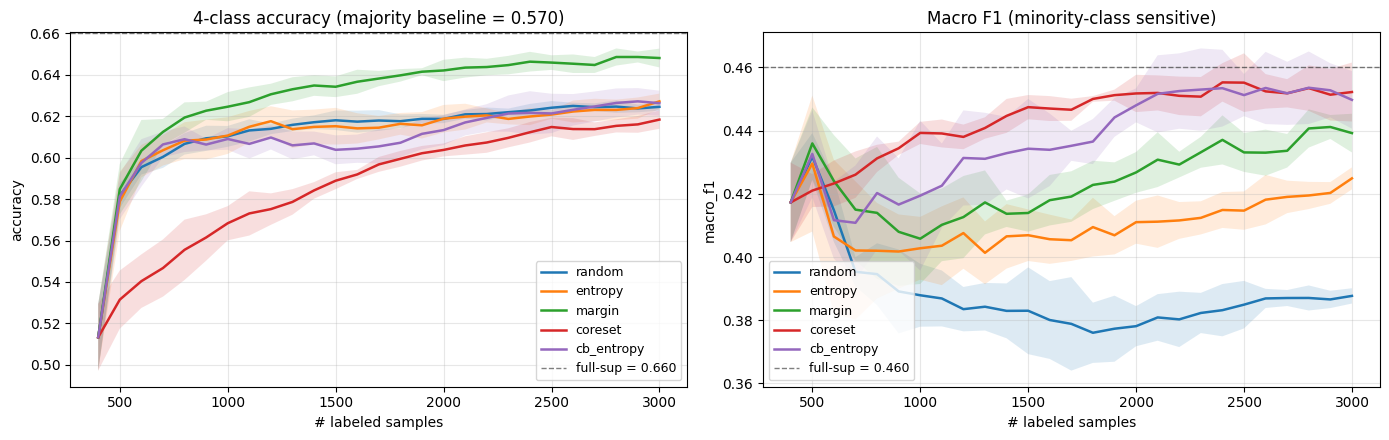

In [28]:
results = pd.concat(all_histories, ignore_index=True)

def plot_learning_curves(results, metric, ax, title, add_full_sup=None):
    for strategy in STRATEGIES:
        sub = results[results['strategy'] == strategy]
        agg = sub.groupby('n_labels')[metric].agg(['mean', 'std']).reset_index()
        ax.plot(agg['n_labels'], agg['mean'], label=strategy, linewidth=1.8)
        ax.fill_between(
            agg['n_labels'],
            agg['mean'] - agg['std'],
            agg['mean'] + agg['std'],
            alpha=0.15,
        )
    if add_full_sup is not None:
        ax.axhline(add_full_sup, color='black', linestyle='--',
                   linewidth=1, alpha=0.5,
                   label=f'full-sup = {add_full_sup:.3f}')
    ax.set_xlabel('# labeled samples')
    ax.set_ylabel(metric)
    ax.set_title(title)
    ax.grid(alpha=0.3)
    ax.legend(fontsize=9)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
plot_learning_curves(results, 'accuracy', axes[0],
                     f'4-class accuracy (majority baseline = {majority_acc:.3f})',
                     add_full_sup=full_acc)
plot_learning_curves(results, 'macro_f1', axes[1],
                     'Macro F1 (minority-class sensitive)',
                     add_full_sup=full_f1)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'bucket_learning_curves.png', dpi=120, bbox_inches='tight')
plt.show()

## Step 8 — Per-Bucket Recall Curves

Which strategies learn which buckets? Rare buckets (UNCERTAIN, SAFE) are where strategy differences matter most.

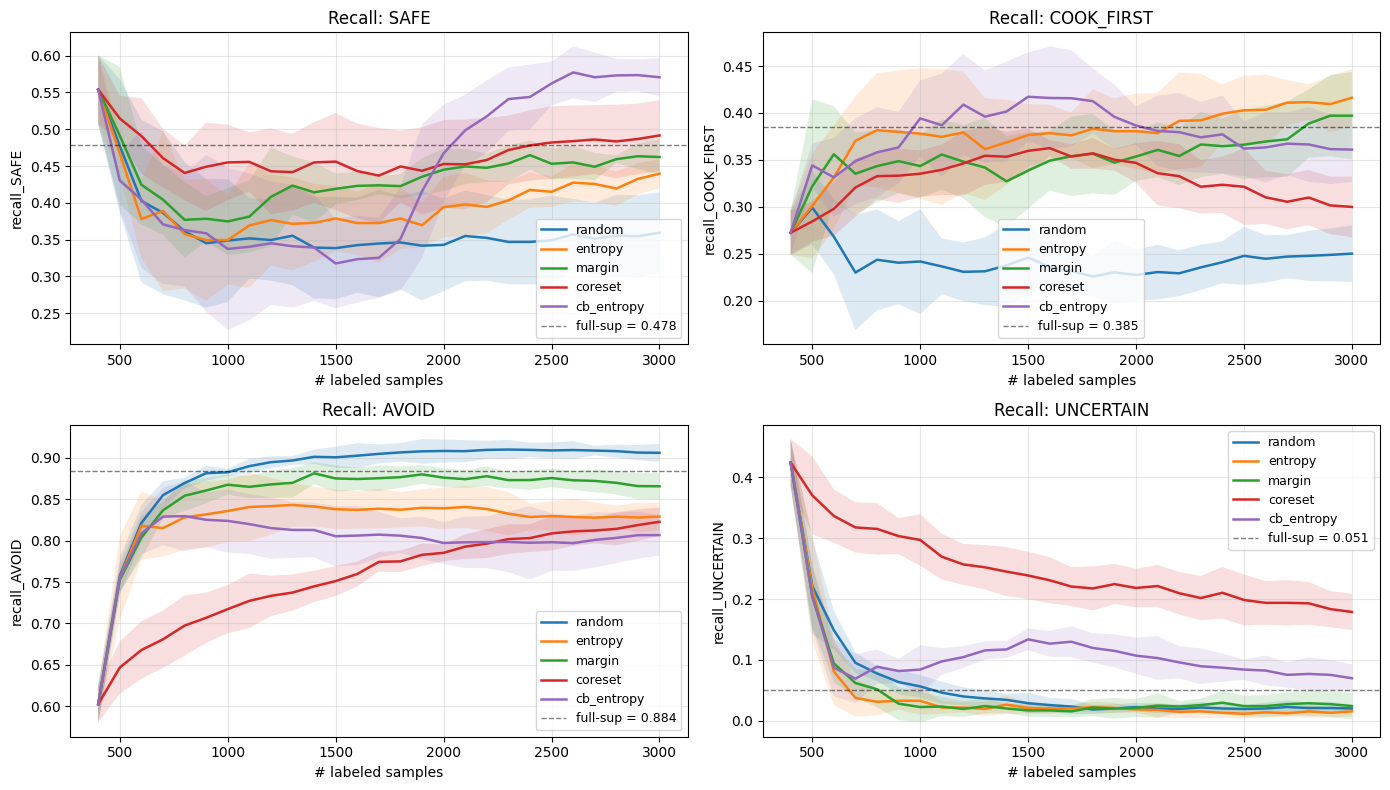

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8))
for ax, b in zip(axes.flat, BUCKET_ORDER):
    metric = f'recall_{b}'
    full_sup_val = per_bucket_recall_full[bucket_to_idx[b]]
    plot_learning_curves(results, metric, ax,
                         f'Recall: {b}',
                         add_full_sup=full_sup_val)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'per_bucket_recall_curves.png', dpi=120, bbox_inches='tight')
plt.show()

## Step 9 — Final-Round Summary Table

Clean table to paste into the report.

In [30]:
final_round = results[results['n_labels'] == MAX_LABELS]

summary_cols = ['accuracy', 'macro_f1'] + [f'recall_{b}' for b in BUCKET_ORDER]
summary = (
    final_round.groupby('strategy')[summary_cols]
               .agg(['mean', 'std'])
)
print(f"Final results at {MAX_LABELS} labels (mean ± std over {N_SEEDS} seeds):\n")
# Rewrite columns for readability
print(summary.round(3).to_string())

# Save to CSV
summary.to_csv(RESULTS_DIR / 'bucket_final_summary.csv')

# Also a compact mean-only version for quick review
mean_only = final_round.groupby('strategy')[summary_cols].mean().round(3)
mean_only.columns = [c.replace('recall_', '') for c in mean_only.columns]
print(f"\nMean only (compact):")
print(mean_only.to_string())

Final results at 3000 labels (mean ± std over 5 seeds):

           accuracy        macro_f1        recall_SAFE        recall_COOK_FIRST        recall_AVOID        recall_UNCERTAIN       
               mean    std     mean    std        mean    std              mean    std         mean    std             mean    std
strategy                                                                                                                          
cb_entropy    0.626  0.006    0.450  0.009       0.571  0.026             0.361  0.035        0.807  0.025            0.070  0.023
coreset       0.618  0.004    0.452  0.009       0.492  0.048             0.300  0.032        0.823  0.017            0.179  0.030
entropy       0.627  0.004    0.425  0.003       0.440  0.019             0.416  0.030        0.829  0.017            0.016  0.008
margin        0.648  0.005    0.439  0.006       0.462  0.025             0.397  0.046        0.866  0.016            0.024  0.022
random        0.624  0.002

## Step 10 — Label Efficiency

How many labels to reach each accuracy/F1 target? Savings vs. random quantify the AL advantage.

In [31]:
def labels_to_reach(results, strategy, seed, metric, target):
    sub = results[(results['strategy']==strategy) & (results['seed']==seed)]
    sub = sub.sort_values('n_labels')
    hit = sub[sub[metric] >= target]
    return int(hit.iloc[0]['n_labels']) if len(hit) > 0 else np.nan

rows = []
for strategy in STRATEGIES:
    l_acc = [labels_to_reach(results, strategy, s, 'accuracy', TARGET_ACC) for s in SEEDS]
    l_f1  = [labels_to_reach(results, strategy, s, 'macro_f1', TARGET_MACRO_F1) for s in SEEDS]
    rows.append({
        'strategy':                 strategy,
        f'labels_to_acc>={TARGET_ACC}':      np.nanmean(l_acc),
        f'labels_to_f1>={TARGET_MACRO_F1}':  np.nanmean(l_f1),
        'reached_acc_target_seeds': int(np.sum(~np.isnan(l_acc))),
        'reached_f1_target_seeds':  int(np.sum(~np.isnan(l_f1))),
    })

efficiency = pd.DataFrame(rows)
random_acc_labels = efficiency.loc[efficiency['strategy']=='random',
                                    f'labels_to_acc>={TARGET_ACC}'].iloc[0]
if not np.isnan(random_acc_labels):
    efficiency['acc_savings_vs_random_%'] = 100 * (1 - efficiency[f'labels_to_acc>={TARGET_ACC}'] / random_acc_labels)
print(f"Label efficiency at acc>={TARGET_ACC}, f1>={TARGET_MACRO_F1}:\n")
print(efficiency.round(1).to_string(index=False))
efficiency.to_csv(RESULTS_DIR / 'label_efficiency.csv', index=False)

Label efficiency at acc>=0.75, f1>=0.6:

  strategy  labels_to_acc>=0.75  labels_to_f1>=0.6  reached_acc_target_seeds  reached_f1_target_seeds
    random                  NaN                NaN                         0                        0
   entropy                  NaN                NaN                         0                        0
    margin                  NaN                NaN                         0                        0
   coreset                  NaN                NaN                         0                        0
cb_entropy                  NaN                NaN                         0                        0


/var/folders/rj/y7tk2xpj4q52mjmjzvvjklc40000gn/T/ipykernel_80519/274266854.py:13: RuntimeWarning: Mean of empty slice
  f'labels_to_acc>={TARGET_ACC}':      np.nanmean(l_acc),
/var/folders/rj/y7tk2xpj4q52mjmjzvvjklc40000gn/T/ipykernel_80519/274266854.py:14: RuntimeWarning: Mean of empty slice
  f'labels_to_f1>={TARGET_MACRO_F1}':  np.nanmean(l_f1),


## Step 11 — Per-Genus Diagnostic

Genus is **not** used for training (we train on bucket labels only) — but we can still check per-genus accuracy as a diagnostic. This tells us whether the classifier handles each genus uniformly or if some genera are systematically harder.

Per-genus accuracy at 3000 labels (mean across seeds):
            Agaricus  Amanita  Boletus  Clitocybe  Mycena  Russula
strategy                                                          
cb_entropy     0.585    0.427    0.725      0.683   0.982    0.377
coreset        0.514    0.491    0.667      0.602   0.995    0.367
entropy        0.521    0.463    0.650      0.743   0.991    0.374
margin         0.503    0.594    0.694      0.703   0.989    0.390
random         0.451    0.571    0.555      0.727   0.999    0.355


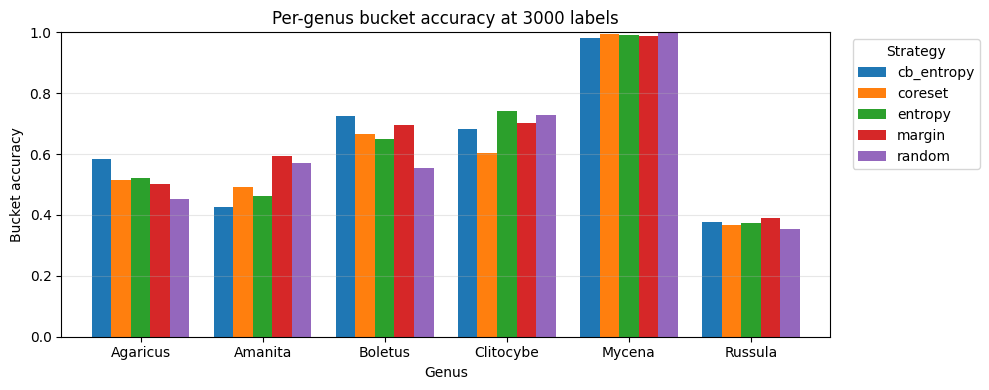

In [32]:
genus_cols = [c for c in results.columns if c.startswith('acc_') and c != 'accuracy']
final_round = results[results['n_labels'] == MAX_LABELS]

per_genus = (
    final_round.groupby('strategy')[genus_cols]
               .mean()
               .round(3)
)
per_genus.columns = [c.replace('acc_', '') for c in per_genus.columns]
print(f"Per-genus accuracy at {MAX_LABELS} labels (mean across seeds):")
print(per_genus.to_string())
per_genus.to_csv(RESULTS_DIR / 'per_genus_bucket_accuracy.csv')

fig, ax = plt.subplots(figsize=(10, 4))
per_genus.T.plot(kind='bar', ax=ax, width=0.8)
ax.set_ylabel('Bucket accuracy')
ax.set_title(f'Per-genus bucket accuracy at {MAX_LABELS} labels')
ax.set_xlabel('Genus')
ax.legend(title='Strategy', bbox_to_anchor=(1.02, 1), loc='upper left')
ax.grid(alpha=0.3, axis='y')
ax.set_ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(RESULTS_DIR / 'per_genus_bucket_accuracy.png', dpi=120, bbox_inches='tight')
plt.show()

## Step 12 — What to Look For

Questions to answer from the figures and tables:

1. **How close do AL strategies get to full supervision?** The dashed black line in the learning curves shows the ceiling at 32,724 labels. If margin hits 90% of that with 3000 labels, you've demonstrated meaningful label efficiency.

2. **Does any strategy clearly beat random on macro F1?** Top-1 accuracy is dominated by AVOID (57% of test). Macro F1 weights all 4 buckets equally — a strategy that learns UNCERTAIN will separate here.

3. **Per-bucket recall breakdown**: expected pattern:
   - AVOID recall: high for all strategies (easy)
   - SAFE recall: moderate; differs by strategy
   - COOK_FIRST recall: moderate
   - UNCERTAIN recall: likely lowest; **cb_entropy should help here if anywhere**

4. **Per-genus diagnostic**: Mycena is 100% AVOID → should be trivial. Russula is 4-way split → hardest. Is there a strategy that closes the Russula gap?

5. **Label efficiency table**: how many labels does each strategy need to reach 75% accuracy? If margin needs 1500 and random needs 2500, that's a clean 40% label savings claim.

Next (if pursued): Notebook 3 — LLM-in-the-loop cascade using Gemini as a noisy pre-labeler, falling back to "expert" (ground truth) only when Gemini is uncertain.
